In [7]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import export_text

In [2]:
df = pd.read_csv('500hits.csv', encoding='latin-1')
df.head()

,PLAYER,YRS,G,AB,R,H,2B,3B,HR,RBI,BB,SO,SB,CS,BA,HOF
0,Ty Cobb,24,3035,11434,2246,4189,724,295,117,726,1249,357,892,178,0.366,1
1,Stan Musial,22,3026,10972,1949,3630,725,177,475,1951,1599,696,78,31,0.331,1
2,Tris Speaker,22,2789,10195,1882,3514,792,222,117,724,1381,220,432,129,0.345,1
3,Derek Jeter,20,2747,11195,1923,3465,544,66,260,1311,1082,1840,358,97,0.310,1
4,Honus Wagner,21,2792,10430,1736,3430,640,252,101,0,963,327,722,15,0.329,1


In [3]:
df = df.drop(columns=['PLAYER', 'CS'])
x = df.iloc[:, 0:13]
y = df.iloc[:, 13]
x_train, x_test, y_train, y_test = train_test_split(x, y, random_state=17, test_size=0.2)
x_train.shape, x_test.shape, y_train.shape, y_test.shape

((372, 13), (93, 13), (372,), (93,))

In [19]:
rf = RandomForestClassifier(n_estimators=10, criterion='entropy', max_depth=2, max_features=4)
rf.fit(x_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",10
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",2
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",4
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_tru

Score: 0.7741935483870968


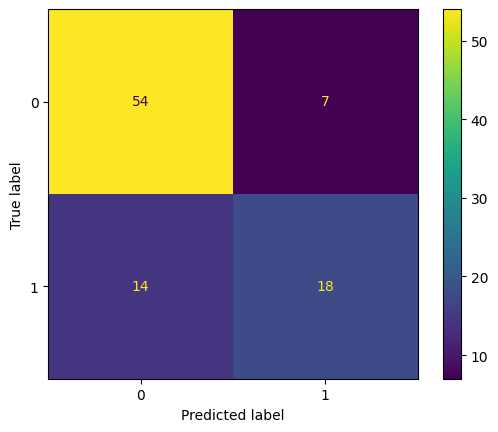

In [20]:
y_pred = rf.predict(x_test)
print(f"Score: {sum(y_pred == y_test) / len(y_test)}")
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot()

In [8]:
for tree in rf.estimators_:
    print(export_text(tree, feature_names=list(x_train.columns)))
    print("_" * 100)

|--- H <= 2210.50
|   |--- 3B <= 63.50
|   |   |--- class: 0.0
|   |--- 3B >  63.50
|   |   |--- class: 0.0
|--- H >  2210.50
|   |--- RBI <= 1487.50
|   |   |--- class: 1.0
|   |--- RBI >  1487.50
|   |   |--- class: 1.0

____________________________________________________________________________________________________
|--- R <= 1192.00
|   |--- H <= 2253.00
|   |   |--- class: 0.0
|   |--- H >  2253.00
|   |   |--- class: 0.0
|--- R >  1192.00
|   |--- G <= 2266.50
|   |   |--- class: 0.0
|   |--- G >  2266.50
|   |   |--- class: 1.0

____________________________________________________________________________________________________
|--- R <= 1198.50
|   |--- BA <= 0.31
|   |   |--- class: 0.0
|   |--- BA >  0.31
|   |   |--- class: 1.0
|--- R >  1198.50
|   |--- R <= 1480.50
|   |   |--- class: 1.0
|   |--- R >  1480.50
|   |   |--- class: 1.0

____________________________________________________________________________________________________
|--- R <= 1254.00
|   |--- BA <= 0.3